# Conda env mapa_temas_evoc

In [1]:
##########################################################
# Cell 1
# Imports 

import os
import sys
import re
import io
import pandas as pd
import numpy as np
np.bool = np.bool_
import dill as pickle

import datamapplot
import evoc
import openai

from sentence_transformers import SentenceTransformer

from umap import UMAP

from collections import Counter

from bertopic import BERTopic
from bertopic.representation import KeyBERTInspired, OpenAI
from bertopic.dimensionality import BaseDimensionalityReduction
from bertopic.representation import LangChain
from bertopic.representation import MaximalMarginalRelevance

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sys.path.append(os.path.abspath("../02_scripts"))
import config


import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device}")

<CONDA_ENV>/lib/python3.11/site-packages/evoc/float_nndescent.py:292: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  points = point_indices[i]


Loading core configurations...
GPU detected: NVIDIA GeForce GTX 1650 with 3.63 GB VRAM
TEST environment detected.

Current Session Configuration Summary:
  - Device: cuda
  - Embedding Model: 'all-mpnet-base-v2'
  - Classification LLM Model: 'RedHatAI/gemma-3-4b-it-quantized.w8a8'
  - Advanced LLM Model (Ext/Synth): 'RedHatAI/gemma-3-4b-it-quantized.w8a8'
  - Data File Path: '<PROJECT_ROOT>/01_dados/df_data_batteries_130k.parquet'

Using cuda


In [2]:
##########################################################
# Cell 2
# Settings

base_path = os.environ.get("BATTERIES_PROJECT_FOLDER", os.path.abspath(".."))

project_path = f"{base_path}/Statistical_study_130k/"
data_path = f"{base_path}/01_dados/"

suffix = "" # "_5k" #  "_500"  #  

#data_file = f"{data_path}/df_short_data_batteries{suffix}.parquet"
data_file = config.DATA_FILE_PATH

image_title = "Batteries_Articles"

embedding_model_name = "intfloat/multilingual-e5-large-instruct"

groqkey = os.environ.get("GROQ_API_KEY", "YOUR_GROQ_API_KEY")
key_proj_perovskita = os.environ.get("OPENAI_API_KEY", "YOUR_OPENAI_API_KEY")


In [ ]:
##########################################################
# Cell 3
# Optional helper cell to create a smaller dataset sample for testing

# data = pd.read_parquet(f"{data_path}df_data_batteries_130k.parquet")
# data = data[["DOI", "Document Title", "Abstract"]]
# data.columns = ["doi", "title", "abstract"]
# data = data.sample(n=5000, random_state=42)
# print(data.shape)
# data.to_parquet(f"{data_path}df_short_data_batteries{suffix}.parquet")
# data.to_csv(f"{data_path}df_short_data_batteries{suffix}.csv")

In [3]:
##########################################################
# Cell 4
# Data loading and preparation

data = pd.read_parquet(data_file)
data = data[[config.COLUMN_DOI, config.COLUMN_TITLE, config.COLUMN_ABSTRACT]]
data[config.COLUMN_TITLE].fillna("", inplace=True)
data[config.COLUMN_ABSTRACT].fillna("", inplace=True)
data.reset_index(drop=True, inplace=True)
print(data.head())

docs = "Title: " + data[config.COLUMN_TITLE] + "\n\nAbstract: " + data[config.COLUMN_ABSTRACT]
pd.options.display.max_colwidth = 200
docs

In [4]:
##########################################################
# Cell 5
# Models and configurations

# Embedding model with a custom prompt focused on battery materials science and functional research objectives.
embedding_model = SentenceTransformer("KaLM-Embedding/KaLM-embedding-multilingual-mini-instruct-v2.5",
                            prompts={
                                "encode": 
                                """
                                    Represent this research text for hierarchical clustering in battery materials science.

                                    PRIORITY ORDER:
                                    1) Primary research FUNCTION (e.g., recycling, electrochemical performance, thermal behavior, modeling, interfacial chemistry).
                                    2) Device DOMAIN (lithium-ion battery, sodium-ion battery, zinc-ion battery, or non-battery system).
                                    3) Active material chemistry (e.g., LiFePO4, ZnMn2O4, SnO2, polymers, graphene composites).
                                    4) Methodological nature (experimental, theoretical, modeling, review).

                                    Strongly separate:
                                    - Recycling/recovery processes
                                    - Thermal transport studies
                                    - Electrochemical performance studies
                                    - Structural/morphological characterization
                                    - Predictive modeling

                                    Do NOT group documents based only on shared material names.
                                    Give highest weight to functional research objective.
                                """,
                            },
                            default_prompt_name="encode",
                            #model_kwargs={'dtype':'auto'}
                            )

# Dimensionality reduction model
umap_model=BaseDimensionalityReduction()

# Use EVoC instead of HDBSCAN for clustering
evoc_model = evoc.EVoC(noise_level=0.12)

# Vectorizer model for tokenization
vectorizer_model = CountVectorizer(
    ngram_range=(1, 3),
    stop_words="english",
    min_df=5
)


# Build representation model to generate topic names.
# Composed of two submodels: "Main" (LLM for short topic labels) and "Aspect1" (KeyBERTInspired for topic keywords).
# OpenAI API client used as LLM to generate topic labels.
client = openai.OpenAI(api_key=key_proj_perovskita)
oa = OpenAI(
    client,
    model="gpt-5-mini",
    delay_in_seconds=2,
    chat=True,
    nr_docs=15,
    diversity=0.5,
    prompt="""
    You will extract a short topic label from given documents and keywords.
Here are two examples of topics you created before:

# Example 1
Sample texts from this topic:
- Traditional diets in most cultures were primarily plant-based with a little meat on top, but with the rise of industrial style meat production and factory farming, meat has become a staple food.
- Meat, but especially beef, is the worst food in terms of emissions.
- Eating meat doesn't make you a bad person, not eating meat doesn't make you a good one.

Keywords: meat beef eat eating emissions steak food health processed chicken
topic: Environmental impacts of eating meat

# Example 2
Sample texts from this topic:
- I have ordered the product weeks ago but it still has not arrived!
- The website mentions that it only takes a couple of days to deliver but I still have not received mine.
- I got a message stating that I received the monitor but that is not true!
- It took a month longer to deliver than was advised...

Keywords: deliver weeks product shipping long delivery received arrived arrive week
topic: Shipping and delivery issues

# Your task
Sample texts from this topic:
[DOCUMENTS]

Keywords: [KEYWORDS]

Based on the information above, extract a short topic label (max 45 chars) in the following format:
topic: <topic_label>"""        
)
# KeyBERTInspired model for keyword representation
kw = KeyBERTInspired()
# Representation model list for BERTopic
#main_representation_model = [kw, oa]
main_representation_model = [oa]
# Model for "Aspect1", which extracts topic keywords
#aspect1_model = [KeyBERTInspired()]
aspect1_model = [kw]
# Representation configuration dict for BERTopic
representation_model = {
    "Main": main_representation_model, # Generates the short topic name
    "Aspect1": aspect1_model,          # Extracts topic keywords
}



# BERTopic model using the prompted embedding model, EVoC for clustering, and the representation configured above.
model = BERTopic(
    embedding_model = embedding_model,
    umap_model=umap_model,
    hdbscan_model = evoc_model,
    vectorizer_model=vectorizer_model,
    #ctfidf_model=
    representation_model = representation_model,
    calculate_probabilities=True,
    verbose=True,
    top_n_words=20,
)

def review_topoc_info_names(df_topics):

    # Prepare a simplified version for the LLM
    # Use Topic and Aspect1 (keywords)
    df_to_refine = df_topics[['Topic', 'Aspect1']].copy()

    # Convert lists to strings for cleaner LLM input
    df_to_refine['Aspect1'] = df_to_refine['Aspect1'].apply(lambda x: ", ".join(x[:10]))

    # Convert DataFrame to markdown string
    table_str = df_to_refine.to_markdown(index=False)
    
    prompt = f"""
    You are an expert taxonomist in Battery Materials Science. 
    I have a table of research topics. 
    
    GOAL: Create unique, highly specific labels (max 45 chars).
    
    CRITICAL RULES:
    1. KEYWORD PRECEDENCE: The label must be strictly derived from the top keywords in 'Aspect1'. 
    2. STRICT LITERALITY:
        Do NOT introduce concepts that are not explicitly present in the keywords.
        Do NOT generalize beyond the provided terms.
        If a term does not appear in the keyword list, do not include it.
    3. CHEMICAL PRECISION:
        If a chemical symbol or full compound name explicitly appears in the keywords,
        you may include it in the label.
        Do NOT infer or construct new compounds.
        Do NOT convert element names into common compounds.
        Use only explicitly stated chemical entities.
    4. FUNCTIONAL ACCURACY: Use a technical term for the process `<T>` (e.g., Recycling, Synthesis, Modeling) ONLY if keywords `<K>` related to that process are clearly present. 
        Example: Use 'Recycling' only if keywords like 'leaching', 'spent', 'waste', or 'recovery' appear.
        Use "Synthesis" only if synthesis-related terms explicitly appear:
        synthesized, synthesis, fabrication, preparation.
    5. NO FILLER: Absolutely NO generic words like 'Experimental', 'Analysis', 'Study', or 'Project'.
    6. UNIQUE DIFFERENTIATION: If two topics share a material, distinguish them by the specific technical action or secondary chemical entity found in the keywords.
    7. Determine the dominant nature of the topic strictly based on keyword frequency and specificity.
        Use only terms that appear directly in the keyword list.
        Do not introduce synonymous abstractions.
        Do not assume latent themes.
        If keywords are material-dominant → use:
        [Specific Material/System] + [Property/Mechanism]
        If process-dominant → use:
        [Process/Technique] + [Target/Material]
        If modeling-dominant → use:
        [Modeling Approach] + [System/Application]
        If nanostructure-dominant → use:
        [Nanostructure Type] + [Material/Application]
    8. Max 45 characters.

    DATA:
    {table_str}
    
    OUTPUT FORMAT:
    Return ONLY a CSV-style list with two columns: Topic | New_Label
    Example:
    0 | Specific Component Characterization
    1 | Process Optimization Study
    """

    response = client.chat.completions.create(
        model="gpt-5-mini",
        messages=[{"role": "system", "content": prompt}],
        #temperature=0.2 # Low temperature for consistency
    )
    
    # Parse response
    output = response.choices[0].message.content
    refined_names = pd.read_csv(io.StringIO(output), sep="|", names=['Topic', 'New_Label'], skipinitialspace=True)
    
    # 2. Clean IDs in case the LLM returned header text
    refined_names['Topic'] = pd.to_numeric(refined_names['Topic'], errors='coerce')
    refined_names = refined_names.dropna(subset=['Topic'])

    # 3. Merge with original dataframe
    df_final = df_topics.merge(refined_names, on='Topic', how='left')

    # 4. Create target columns
    # New_Representation: pure label
    df_final['New_Representation'] = df_final['New_Label']

    # New_Name: topic ID + new label
    df_final['New_Name'] = df_final['Topic'].astype(str) + "_" + df_final['New_Label']

    # Drop helper column
    df_final = df_final.drop(columns=['New_Label'])

    return df_final

def create_topic_description(df_topics):

    # Create a one-sentence description of the papers expected in each topic
    # Use New_Name (topic name) and Aspect1 (keywords)
    df_to_refine = df_topics[['Topic', 'New_Name', 'Aspect1']].copy()

    # Convert lists to strings for cleaner LLM input
    df_to_refine['Aspect1'] = df_to_refine['Aspect1'].apply(lambda x: ", ".join(x[:10]))

    # Convert DataFrame to markdown string
    table_str = df_to_refine.to_markdown(index=False)
    
    prompt = f"""

    You are a specialist in Battery Materials Science.
    I have a table of research topics containing the columns: 
        - Topic: the topic numbar just as a reference,
        - New_Name: the name of tje topic,
        - Aspect1: keywords referring to the topic content
    Based ONLY on the provided information, write ONE technical sentence (max 40 words) describing the main research focus of this topic.

    STRICT RULES:
    - Use only terms that appear in the providesd inforamtion.
    - Mention the primary material if present.
    - Mention the main process or technique if present.
    - Do NOT use generic phrases like: data trends, stakeholder impacts, strategic improvements, decision-making, organizational efficiency.
    - Do NOT generalize beyond the provided terms.
    - Start the phrase directly with the main research focus, e.g., “Focuses on the recovery of...” or “Investigates the stability of...”. Avoid starting with generic expressions like “The research focuses...”.
    - Be technically specific.

    Output ONLY the sentence.

    DATA:
    {table_str}
    
    OUTPUT FORMAT:
    Return ONLY a CSV-style list with two columns: Topic | Description
    Example:
    0 | Specific Component Characterization
    1 | Process Optimization Study
    """

    response = client.chat.completions.create(
        model="gpt-5-mini",
        messages=[{"role": "system", "content": prompt}],
        #temperature=0.2 # Low temperature for consistency
    )


    # Parse response
    output = response.choices[0].message.content
    refined_names = pd.read_csv(io.StringIO(output), sep="|", names=['Topic', 'Description'], skipinitialspace=True)
    
    # 2. Clean IDs in case the LLM returned header text
    refined_names['Topic'] = pd.to_numeric(refined_names['Topic'], errors='coerce')
    refined_names = refined_names.dropna(subset=['Topic'])

    # 3. Merge with original dataframe
    df_final = df_topics.merge(refined_names, on='Topic', how='left')

    # # 4. Create target columns
    # df_final['Description'] = df_final['New_Label']

    # # New_Name: topic ID + new label
    # df_final['New_Name'] = df_final['Topic'].astype(str) + "_" + df_final['New_Label']

    # # Drop helper column
    # df_final = df_final.drop(columns=['New_Label'])

    return df_final


README.md: 0.00B [00:00, ?B/s]

Default prompt name is set to 'encode'. This prompt will be applied to all `encode()` calls, except if `encode()` is called with `prompt` or `prompt_name` parameters.


In [5]:
##########################################################
# Cell 6
# Generate or load document embeddings

# embs = embedding_model.encode(docs,show_progress_bar=True)
# with open(f'{project_path}embs_pred{suffix}.pkl', 'wb') as handle:
#     pickle.dump(embs, handle, protocol=pickle.HIGHEST_PROTOCOL)

with open(f'{project_path}/embs_pred{suffix}.pkl', 'rb') as handle:
    embs = pickle.load(handle)

In [6]:
##########################################################
# Cell 7
# Fit documents with BERTopic model and save results

topics, probs = model.fit_transform(docs,embeddings=embs)

with open(f'{project_path}topics_pred{suffix}.pkl', 'wb') as handle:
    pickle.dump(topics, handle, protocol=pickle.HIGHEST_PROTOCOL)
with open(f'{project_path}probs_pred{suffix}.pkl', 'wb') as handle:
    pickle.dump(probs, handle, protocol=pickle.HIGHEST_PROTOCOL)
model.save(f'{project_path}model_pred{suffix}', serialization="safetensors", save_ctfidf=True, save_embedding_model=embedding_model)


# with open(f'{project_path}topics_pred{suffix}.pkl', 'rb') as handle:
#     topics = pickle.load(handle)
# with open(f'{project_path}probs_pred{suffix}.pkl', 'rb') as handle:
#     probs = pickle.load(handle)
# model = BERTopic.load(f'{project_path}model_pred{suffix}', embedding_model=embedding_model)

topic_info = model.get_topic_info()
topic_info = review_topoc_info_names(topic_info)
#topic_info["New_Name"] = topic_info["Name"]
#topic_info["New_Representation"] = topic_info["Representation"]
topic_info = create_topic_description(topic_info)
topic_info

In [4]:
##########################################################
# Cell 8
# Iterate over hierarchical cluster layers to extract topic names, keywords, and assignments

# topic_infos = []
# current_topics_infos = []
# layer_count = 0
# for layer in range(len(model.hdbscan_model.cluster_layers_)):

#     current_topics = model.hdbscan_model.cluster_layers_[layer]
#     topics = range(len(set(current_topics))-1)

#     if len(topics) < 100:
#         topic_embeddings = np.array([embs[current_topics == topic].mean(axis=0) for topic in topics])
#         similarity = cosine_similarity(embs,topic_embeddings)
#         new_topics = similarity.argmax(axis=1)
#         mask =  current_topics == -1
#         current_topics[mask] = new_topics[mask]

#         model.update_topics(docs = docs,
#                             topics = current_topics,  
#                             representation_model = representation_model)


#         #topic_info = review_topoc_info_names(model.get_topic_info())
#         topic_info = model.get_topic_info()
#         topic_info = review_topoc_info_names(topic_info)
#         #topic_info["New_Name"] = topic_info["Name"]
#         #topic_info["New_Representation"] = topic_info["Representation"]
#         topic_info = create_topic_description(topic_info)
#         topic_infos.append(topic_info)
#         current_topics_infos.append(current_topics)

#         data[f'topic_{layer_count}'] = current_topics

#         print(f"\n\nLayer {layer_count}")
#         print(topic_info.head(10))
        
#         layer_count += 1

# with open(f'{project_path}/topic_infos{suffix}.pkl', 'wb') as handle:
#     pickle.dump(topic_infos, handle, protocol=pickle.HIGHEST_PROTOCOL)
# with open(f'{project_path}/current_topics_infos{suffix}.pkl', 'wb') as handle:
#     pickle.dump(current_topics_infos, handle, protocol=pickle.HIGHEST_PROTOCOL)
# data.to_csv(f'{project_path}/data_com_topicos_pred{suffix}.csv',sep='\t',index=False)

with open(f'{project_path}/topic_infos{suffix}.pkl', 'rb') as handle:
    topic_infos = pickle.load(handle)
with open(f'{project_path}/current_topics_infos{suffix}.pkl', 'rb') as handle:
    current_topics_infos = pickle.load(handle)
data = pd.read_csv(f'{project_path}/data_com_topicos_pred{suffix}.csv',sep='\t')

data

In [5]:
##########################################################
# Cell 9
# Reduce embedding dimensionality with UMAP for cluster visualization

# reduced_embeddings = UMAP(
#                             n_components=2  # larger values generate more clusters
#                           ).fit_transform(embs)
# with open(f'{project_path}/reduced_embeddings{suffix}.pkl', 'wb') as handle:
#     pickle.dump(reduced_embeddings, handle, protocol=pickle.HIGHEST_PROTOCOL)

with open(f'{project_path}/reduced_embeddings{suffix}.pkl', 'rb') as handle:
    reduced_embeddings = pickle.load(handle)

  0%|          | 0/500 [00:00<?, ?it/s]

Resetting positions to accord with alignment


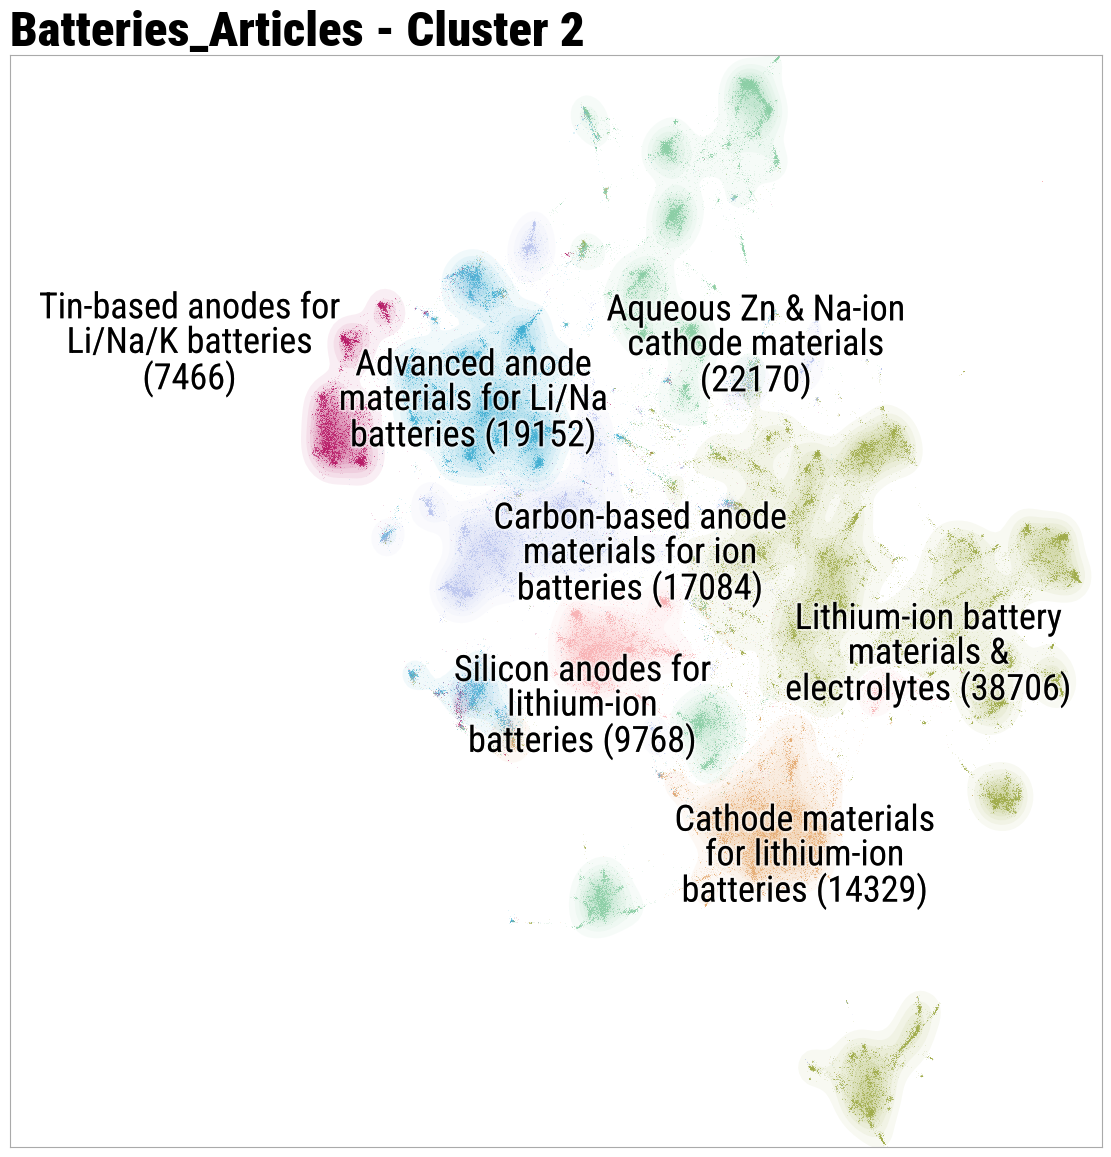

In [8]:
##########################################################
# Cell 10
# Save cluster visualizations using datamapplot


# Iterate over each topic layer in 'topic_infos'
new_clusters_name = []
for i, topic_info in enumerate(topic_infos):
    # 1. Get the list of topic IDs for this layer
    topic_ids = data[f'topic_{i}'].tolist()
    
    # 2. Count how many times each ID appears in the dataset
    counts = Counter(topic_ids)

    # 3. Create a mapping dictionary: ID -> Formatted name
    # This avoids repeated DataFrame lookups inside the loop
    name_mapping = {}
    for _, row in topic_info.iterrows():
        topic_id = row['Topic']
        name = row['Representation'][0]
        count = counts[topic_id]
        
        # Format with LaTeX subscripts and count
        formatted_name = f"{name} ({count})".replace("MoS2", r"$\mathrm{MoS_2}$").replace("TiO2", r"$\mathrm{TiO_2}$").replace("LiFePO4", r"$\mathrm{LiFePO_4}$")
        name_mapping[topic_id] = formatted_name

    # 4. Build final label list for this layer using the mapping
    # If an ID is not in the mapping (rare), keep the original ID
    formatted_sublist = [name_mapping.get(tid, str(tid)) for tid in topic_ids]

    # 5. Append to results list
    new_clusters_name.append(formatted_sublist)


for i, cluster_estudado in enumerate(new_clusters_name):

    # Generate plot for selected cluster layers
    cc = Counter(cluster_estudado).items()
    if i>=2: #len(cc) == len(topic_infos[i]):
        fig, ax = datamapplot.create_plot(
            reduced_embeddings,
            cluster_estudado,
            figsize=(11, 11),
            title=f"{image_title} - Cluster {i}",
            #use_medoids=False,
            label_over_points=True,
            label_wrap_width=20, #35, # 
            #dynamic_label_size=True,
            #dynamic_label_size_scaling_factor=0.5,
            #max_font_size=14,
            #min_font_size=13,
            label_font_size=26,
            color_label_text=False, #True, 
            min_font_weight=500,
            max_font_weight=501,
            font_family="Roboto Condensed"
        )

        fig.savefig(f"{project_path}{image_title}_cluster_{i}{suffix}.pdf", bbox_inches="tight")

In [14]:
# Column settings
cols = [config.COLUMN_DOI, config.COLUMN_TITLE, config.COLUMN_ABSTRACT]
for i in range(len(topic_infos)):
    cols.append(f'topic_{i}')

tmp = data[cols].copy()

for i, topic_info in enumerate(topic_infos):
    print(f"Preparing Layer {i}...")
    
    file_name = f'{project_path}/papers_pred_cluster{i}{suffix}.xlsx'
    # Use 'xlsxwriter' if installed, or 'openpyxl' otherwise
    writer = pd.ExcelWriter(file_name, engine='xlsxwriter') 
    
    # 1. Robust Mapping of IDs to Names
    # Create a dictionary where the key is the topic number (e.g., -1, 0, 1)
    name_map = dict(zip(topic_info['Topic'], topic_info['Name']))
    
    # 2. "Topics" Summary Sheet
    kw_col = 'Aspect1' if 'Aspect1' in topic_info.columns else 'Representation'
    description_col = 'Description' 
    df_topics_summary = topic_info[['Topic', 'Count', 'Name',kw_col, description_col]].copy()
    
    df_topics_summary['keywords'] = df_topics_summary[kw_col].apply(
        lambda x: ", ".join(x) if isinstance(x, list) else str(x)
    )
    
    # Optional LaTeX formatting in summary name
    #df_topics_summary['New_Name'] = df_topics_summary['New_Name'].str.replace("Ni3S2", r"$\mathrm{Ni_3S_2}$", regex=False)
    
    # Ensure summary follows numerical order of Topic ID
    df_topics_summary.sort_values(by="Topic", inplace=True)
    df_topics_summary[['Topic', 'Count', 'Name', 'keywords', description_col]].to_excel(writer, sheet_name="Topics", index=False)
    
    # 3. Create sheets for each topic with validated names
    # Group by ID and iterate over each group
    for topic_id, grp in tmp.groupby(f'topic_{i}'):
        
        # Look up the topic name corresponding to topic_id
        topic_name = name_map.get(topic_id, f"Topic_{topic_id}")
        
        # Clean for Excel (max 31 characters and no forbidden characters)
        # Replace forbidden characters with '_'
        clean_name = re.sub(r'[\\/*?:\[\]]', '_', str(topic_name))
        sheet_label = clean_name[:31] 
        
        # Optional: Add count to sheet name for visual verification
        # sheet_label = f"{topic_id} ({len(grp)})"[:31]

        # Save group (documents) to the validated sheet name
        grp.to_excel(writer, sheet_name=sheet_label, index=False)
        
    writer.close()
    print(f"Layer {i} file completed.")

Preparing Layer 0...
Layer 0 file completed.
Preparing Layer 1...
Layer 1 file completed.
Preparing Layer 2...
Layer 2 file completed.
